# Masking Clouds and Bad Pixels with Python

Before you measure anything in a satellite image, you need to know which pixels you can trust. Clouds, haze, and cloud shadow all change the reflectance a sensor records. 

Wyvern L2A products has two masks that tell you where those problem pixels are. In this tutorial we will work through both of them.

By the end you will know how to:

- Load L2A imagery together with its quality masks
- Read what each mask band means
- Apply a mask and compare the result against the original scene
- Check how much usable data you have left

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Nrevyw/wyvern-public-resources/blob/main/tutorial-notebooks/cloud-and-data-masks/cloud_and_data_masks.ipynb)

## The two masks

**Data Mask** has four bands, one each for clear, cloud, haze, and cloud shadow. A value of `1` means the pixel is flagged for that condition and `255` means NoData. Band 1, the clear band, is the one we  will use most.

**Pixel Quality Mask** describes each band separately. It has one quality band for every image band, where `0` means no documented quality condition, `1` means the value was interpolated, and `255` means NoData. Interpolated means the value was filled in rather than measured directly, so a pixel can be perfectly clear of cloud and still be interpolated in one band.

Details on both are here in the Product Guide: [Usable Data Mask](https://guide.wyvern.space/data-product-guide/file-formats/usable-data-mask/) and [Pixel Quality Mask](https://guide.wyvern.space/data-product-guide/file-formats/pixel-quality-mask/).

## Packages

We will use the following packages in this tutorial:

- **Rasterio** (which relies on GDAL) opens the GeoTIFF files and reads bands into arrays, along with metadata like the image size and the coordinate reference system.
- **NumPy** handles the array math. Comparing a mask against the imagery is comparing two arrays of the same shape.
- **Matplotlib** displays the scene and the masks.
- **Requests** downloads the STAC metadata and the files.

You can install any missing packages with `pip install rasterio numpy matplotlib requests`.

## Getting started

The notebook installs its own dependencies, so there is nothing to set up in advance.

- **Google Colab (easiest):** open the notebook using the Colab badge above, then run the cells top to bottom.
- **Local Jupyter:** open the notebook in JupyterLab or VS Code (Python 3.10+) and run it.

In [1]:
%pip -q install rasterio numpy matplotlib requests

Note: you may need to restart the kernel to use updated packages.


In [2]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import rasterio
import requests
from rasterio.windows import Window

## Scene description

The Data Mask section uses a Dragonette-004 L2A scene over Sandusky Bay on the Lake Erie shore in Ohio, captured on 23 September 2025. It has cloud, haze, and cloud shadow all present.

The Pixel Quality Mask section uses a Dragonette-003 L2A scene over the Volga near Saratov, Russia, captured on 24 January 2025. The Ohio scene has no interpolated pixels in any band. We apply both masks together at the end of that section.

We will read everything from the [STAC item](https://wyvern-odp.com/wyvern_dragonette-004_20250923T153600_c87b879b_l2a/wyvern_dragonette-004_20250923T153600_c87b879b_l2a.json) for each scene. STAC is a way of describing satellite imagery, and the item lists the links for the imagery and both masks, the wavelength of every band, the reflectance scale factor, and the NoData value. Since we are pulling this from the metadata, you can run this on any other Wyvern scene by just changing the URL. You can find more scenes to try on the [Wyvern Open Data Program](https://opendata.wyvern.space/#/?.language=en).

In [3]:
STAC_URL = (
    "https://wyvern-odp.com/wyvern_dragonette-004_20250923T153600_c87b879b_l2a/"
    "wyvern_dragonette-004_20250923T153600_c87b879b_l2a.json"
)


def load_item(stac_url: str) -> dict:
    """
    Fetch the STAC item describing a scene.

    Args:
        stac_url: Link to the scene's STAC JSON file.

    Returns:
        The STAC item as a dictionary.
    """
    response = requests.get(stac_url, headers={"User-Agent": "Mozilla/5.0"}, timeout=60)
    response.raise_for_status()
    return response.json()


item = load_item(STAC_URL)
image_asset = item["assets"]["Cloud optimized GeoTiff"]

wavelengths_nm = np.array(
    [band["center_wavelength"] * 1000 for band in image_asset["eo:bands"]]
)
scale = image_asset["raster:bands"][0]["scale"]
nodata = image_asset["raster:bands"][0]["nodata"]

print("Scene:", item["id"])
print("Bands:", len(wavelengths_nm))
print("Reflectance scale:", scale)
print("NoData:", nodata)
print("Cloud cover (STAC):", item["properties"].get("eo:cloud_cover"), "%")

Scene: wyvern_dragonette-004_20250923T153600_c87b879b_l2a
Bands: 31
Reflectance scale: 0.0001
NoData: 65535
Cloud cover (STAC): 6.38 %


The cloud cover figure printed above comes from the scene metadata. We can later count the cloud flagged pixels to see if they agree.

## Download the tutorial files

Now we can download the files we need for this scene: the L2A GeoTIFF and the Data Mask. The URLs all came from the STAC item in the previous cell.
Anything already downloaded gets skipped.

In [4]:
def download_assets(item: dict, keys: list[str]) -> dict[str, Path]:
    """
    Download the named assets into a folder named after the scene.

    Args:
        item: A STAC item, as returned by load_item().
        keys: Asset names to download, for example "Data Mask".

    Returns:
        A dictionary mapping each asset name to its downloaded file path.
    """
    folder = Path(item["id"])
    folder.mkdir(exist_ok=True)

    paths = {}
    for key in keys:
        path = folder / (key.lower().replace(" ", "_") + ".tiff")
        paths[key] = path
        if path.exists():
            print(f"Already downloaded: {path}")
            continue

        print(f"Downloading {path}...")
        url = item["assets"][key]["href"]
        with requests.get(
            url, headers={"User-Agent": "Mozilla/5.0"}, stream=True, timeout=300
        ) as response:
            response.raise_for_status()
            with path.open("wb") as file:
                for chunk in response.iter_content(chunk_size=1024 * 1024):
                    if chunk:
                        file.write(chunk)
    return paths


paths = download_assets(item, ["Cloud optimized GeoTiff", "Data Mask"])
IMAGE_PATH = paths["Cloud optimized GeoTiff"]
DATA_MASK_PATH = paths["Data Mask"]
print("Downloads complete")

Already downloaded: wyvern_dragonette-004_20250923T153600_c87b879b_l2a\cloud_optimized_geotiff.tiff
Already downloaded: wyvern_dragonette-004_20250923T153600_c87b879b_l2a\data_mask.tiff
Downloads complete


## Looking at the scene

We will use 650, 550, and 490 nm for red, green, and blue. Masking works the same way regardless of which bands we display.

Two steps happen before the image is ready to look at. First we replace NoData pixels with `np.nan` so they stay out of any calculation, then we apply the reflectance scale factor to turn the stored integers into reflectance values between 0 and 1. The order matters here. If you scale first, the NoData value gets scaled too.
We also stretch each channel between its 2nd and 98th percentile so the contrast looks reasonable. That is a display step only. The `mask` argument on the stretch function lets us choose which pixels those percentiles are measured from.

Display bands (R, G, B): [650, 549, 490] nm


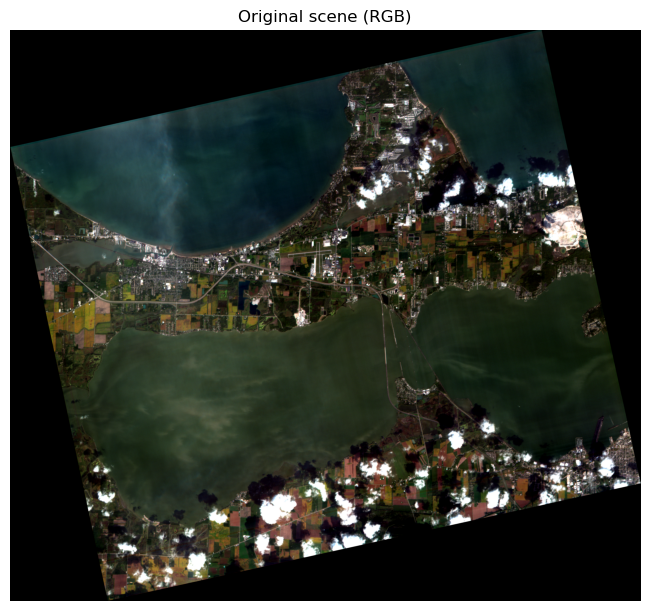

In [5]:
def nearest_band(wavelengths: np.ndarray, wavelength_nm: int) -> int:
    """
    Find the band closest to a requested wavelength.

    Args:
        wavelengths: Centre wavelength of every band, in nanometres.
        wavelength_nm: Target wavelength in nanometres.

    Returns:
        The 1-based band index rasterio needs to read that band.
    """
    return int(np.argmin(np.abs(wavelengths - wavelength_nm)) + 1)


def stretch(channel: np.ndarray, mask: np.ndarray | None = None) -> np.ndarray:
    """
    Stretch an image band to the 0-1 range for display.

    Values below the 2nd percentile and above the 98th are clipped, which stops a
    few unusually dark or bright pixels from washing out the rest of the image.

    Args:
        channel: A 2D image band containing reflectance values.
        mask: Optional boolean array selecting which pixels the percentiles are
            measured over. The whole band is used when it is left out.

    Returns:
        The stretched band, with values between 0 and 1.
    """
    sample = channel if mask is None else channel[mask]
    low, high = np.nanpercentile(sample, [2, 98])
    return np.clip((channel - low) / max(high - low, 1e-6), 0, 1)


rgb_bands = [nearest_band(wavelengths_nm, nm) for nm in (650, 550, 490)]
print(
    "Display bands (R, G, B):", [round(wavelengths_nm[i - 1]) for i in rgb_bands], "nm"
)

with rasterio.open(IMAGE_PATH) as src:
    image_width, image_height = src.width, src.height
    image_transform, image_crs = src.transform, src.crs
    if src.count != len(wavelengths_nm):
        print("Warning: image band count does not match the STAC metadata")
    image_raw = src.read(rgb_bands)

# Replace NoData before applying the reflectance scale.
reflectance = image_raw.astype(np.float32)
reflectance[image_raw == nodata] = np.nan
reflectance *= scale

rgb = np.moveaxis(reflectance, 0, -1)
valid_display = np.all(np.isfinite(rgb), axis=2)

rgb_display = np.stack([stretch(rgb[:, :, i]) for i in range(3)], axis=-1)
rgb_display = np.nan_to_num(rgb_display, nan=0)

fig, ax = plt.subplots(figsize=(8, 6), layout="constrained")
ax.imshow(rgb_display)
ax.set_title("Original scene (RGB)")
ax.axis("off")
plt.show()

The bright patches in the scene are the clouds, which are easy to spot. There are also darker patches offset from each cloud where its shadow falls. 

Note that `valid_display` is built from the three bands we are showing, so it only tells if those three are valid. If you plan to use the full cube, build that check from all the bands you want to analyse.

## Inspecting the Data Mask

The Data Mask has four bands, in this order: clear, cloud, haze, and cloud shadow. A value of `1` means the pixel is flagged for that condition, and `255` is NoData.

Before trusting the mask, it is worth checking that it lines up with the image. A mask of the wrong size, or one with a different transform, could shift your flags across the scene. The checks below compare the width, height, coordinate reference system, and transform against the imagery, and print a warning.

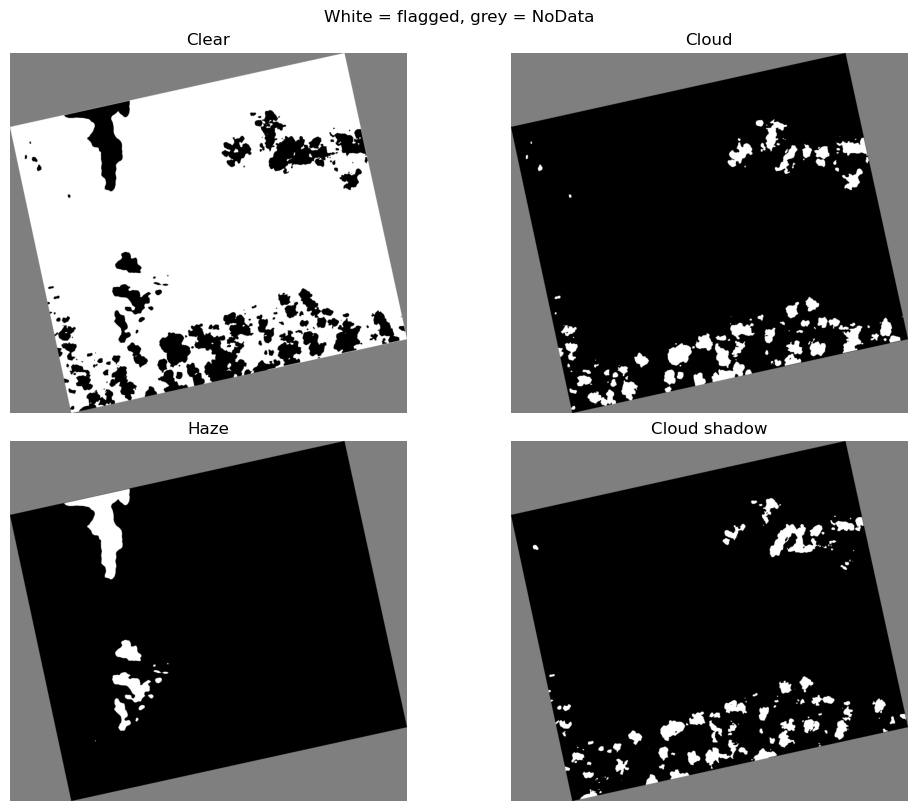

In [6]:
with rasterio.open(DATA_MASK_PATH) as src:
    if (src.width, src.height, src.crs) != (image_width, image_height, image_crs):
        print("Warning: Data Mask size or CRS does not match the image")
    if not src.transform.almost_equals(image_transform):
        print("Warning: Data Mask is not aligned with the image")
    data_mask = src.read()

# Grey for NoData so it cannot be mistaken for a flagged or an unflagged pixel.
grey = plt.cm.gray.copy()
grey.set_bad("0.5")

labels = ["Clear", "Cloud", "Haze", "Cloud shadow"]
fig, axes = plt.subplots(2, 2, figsize=(10, 8), layout="constrained")
for i, ax in enumerate(axes.flat):
    flagged = np.ma.masked_where(data_mask[i] == 255, data_mask[i] == 1)
    ax.imshow(flagged, cmap=grey, vmin=0, vmax=1)
    ax.set_title(labels[i])
    ax.axis("off")
fig.suptitle("White = flagged, grey = NoData")
plt.show()

Compare these four panels against the RGB image above.

The clear panel is close to the inverse of the other three combined. The cloud panel lines up with the bright patches you can see by eye and the cloud shadow panel sits slightly offset from it.

The haze panel shows one large patch that is away from the clouds, and in the RGB that area reads as a slightly washed out region.


The following figure shows all three where cloud is red, haze is green, cloud shadow is blue.

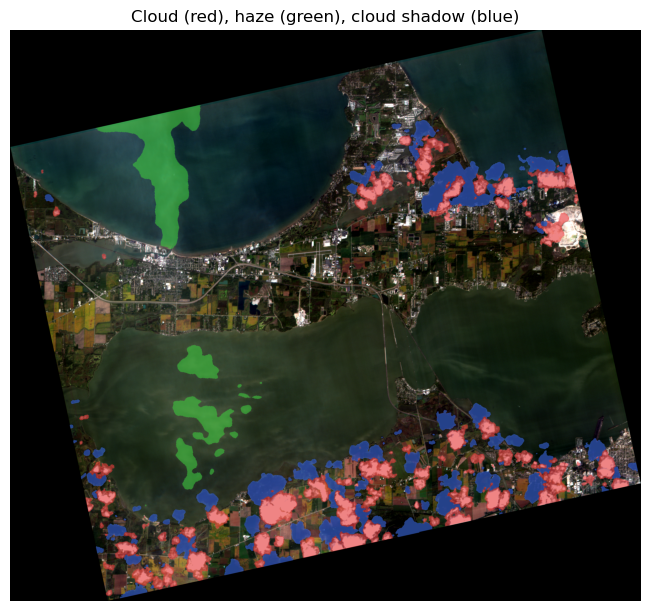

In [7]:
composite = rgb_display.copy()
for i, colour in [
    (1, [0.90, 0.20, 0.20]),
    (2, [0.24, 0.78, 0.24]),
    (3, [0.24, 0.43, 0.90]),
]:
    flagged = data_mask[i] == 1
    composite[flagged] = 0.4 * composite[flagged] + 0.6 * np.array(colour)

fig, ax = plt.subplots(figsize=(8, 6), layout="constrained")
ax.imshow(composite)
ax.set_title("Cloud (red), haze (green), cloud shadow (blue)")
ax.axis("off")
plt.show()

## Applying the Data Mask

To apply the mask we keep only the pixels that are flagged clear and have valid reflectance, then compare the result side by side with the original.

Excluded pixels show up black here.

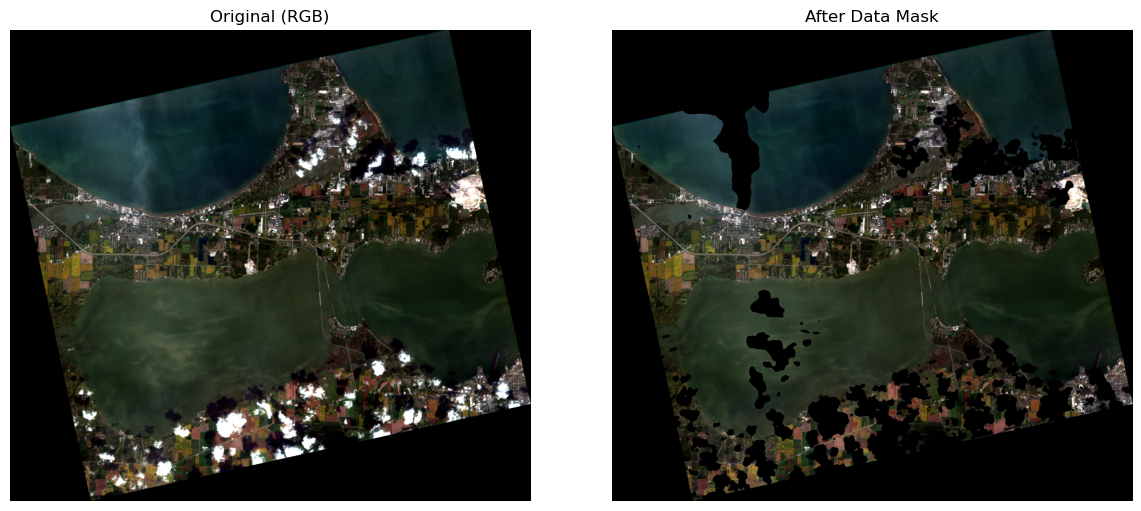

In [8]:
clear = (data_mask[0] == 1) & valid_display
rgb_clear = np.where(clear[:, :, None], rgb_display, 0)

fig, axes = plt.subplots(1, 2, figsize=(12, 5), layout="constrained")
for ax, image, title in zip(
    axes,
    [rgb_display, rgb_clear],
    ["Original (RGB)", "After Data Mask"],
):
    ax.imshow(image)
    ax.set_title(title)
    ax.axis("off")
plt.show()

The clouds and their shadows are gone, and the rest of the scene is untouched.

One thing to watch after masking is the stretch. We set the display range from the brightest and darkest pixels in the whole scene, and the brightest ones were clouds. With the clouds removed, that range is wider than it needs to be, so the ground can come out looking dimmer.

The mask argument on our stretch function measures the range from the clear pixels instead.

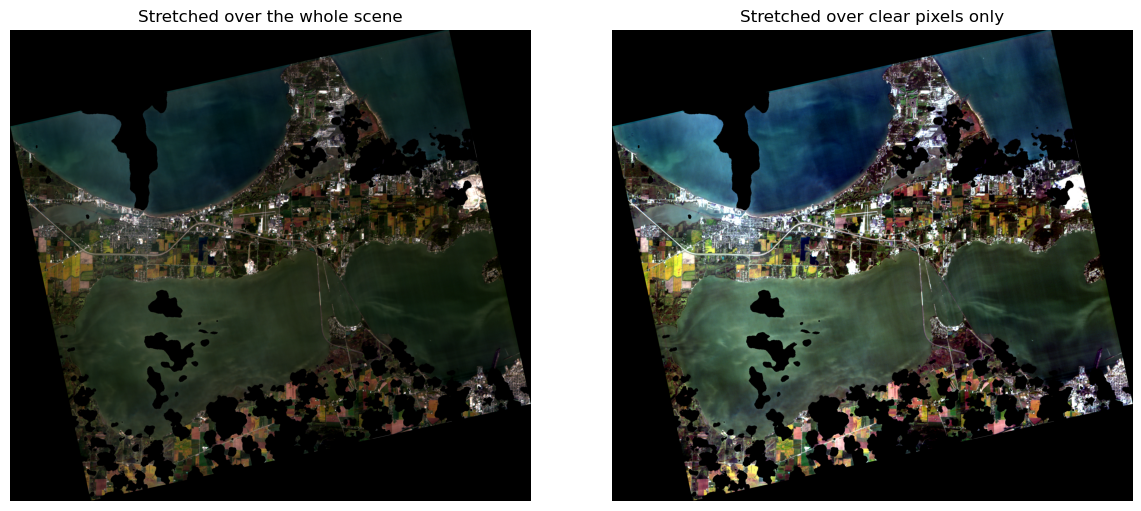

In [9]:
# Measure the stretch over clear pixels instead of the whole scene.
rgb_restretched = np.stack([stretch(rgb[:, :, i], clear) for i in range(3)], axis=-1)
rgb_restretched = np.nan_to_num(rgb_restretched, nan=0)
rgb_clear_restretched = np.where(clear[:, :, None], rgb_restretched, 0)

fig, axes = plt.subplots(1, 2, figsize=(12, 5), layout="constrained")
for ax, image, title in zip(
    axes,
    [rgb_clear, rgb_clear_restretched],
    ["Stretched over the whole scene", "Stretched over clear pixels only"],
):
    ax.imshow(image)
    ax.set_title(title)
    ax.axis("off")
plt.show()

The right panel is brighter and the colours are stronger, which is the same data displayed over a narrower range. How large this difference is depends on how much cloud was in the scene to begin with.

## Checking what is left

We can count what survived after masking.

Every percentage below is measured against the valid pixels rather than the whole file, so the NoData border does not count towards any of them.

Here we can compare our own cloud count against the cloud cover figure from the scene metadata.

In [10]:
n_valid = np.count_nonzero(valid_display)
if n_valid == 0:
    raise ValueError("No valid image pixels in this scene")

print(f"Valid image pixels: {n_valid:,}")
print(f"Kept after Data Mask: {100 * np.count_nonzero(clear) / n_valid:.2f}%")
print()
for i, label in enumerate(["Cloud", "Haze", "Shadow"], start=1):
    flagged = np.count_nonzero((data_mask[i] == 1) & valid_display)
    print(f"{label} flagged: {100 * flagged / n_valid:.2f}%")
print()
print("Cloud cover reported in STAC:", item["properties"].get("eo:cloud_cover"), "%")

if not np.all(rgb_clear[~clear] == 0):
    print("Warning: some excluded pixels are not black in the display")

Valid image pixels: 15,685,581
Kept after Data Mask: 85.11%

Cloud flagged: 6.38%
Haze flagged: 3.20%
Shadow flagged: 5.31%

Cloud cover reported in STAC: 6.38 %


Compare the cloud flagged percentage against the cloud cover value from the metadata. They may not match exactly, but they should land in the same range. 

## Inspecting the Pixel Quality Mask

A hyperspectral pixel is really a stack of values, one per band, and a problem can affect some of those values and not others. That is what the Pixel Quality Mask is for. It has one quality band for every image band, where `0` means no documented quality condition, `1` means the value was interpolated, and `255` means NoData.

Interpolated means the value was estimated from its neighbours rather than measured. That is not automatically a reason to throw the pixel out, but it is something you may want to know about, especially if the interpolated band is one your index depends on.

This section uses the Saratov scene, since the Ohio scene has no interpolated pixels in any of its bands. The code below is the same whichever scene you point it at.

We check every quality band rather than only the three we are displaying, since a band can be affected without showing up in the RGB. Reading one band at a time keeps memory use low. Later, when we zoom in on the flagged pixels, we read only that window of the imagery rather than the whole scene. Rasterio does this through `Window`, and it is useful for large scenes where you only need part of the image.

In [11]:
QUALITY_STAC_URL = (
    "https://wyvern-odp.com/wyvern_dragonette-003_20250124T073519_a462860b_l2a/"
    "wyvern_dragonette-003_20250124T073519_a462860b_l2a.json"
)

q_item = load_item(QUALITY_STAC_URL)
q_paths = download_assets(
    q_item, ["Cloud optimized GeoTiff", "Pixel Quality Mask", "Data Mask"]
)

q_asset = q_item["assets"]["Cloud optimized GeoTiff"]
q_wavelengths = np.array(
    [band["center_wavelength"] * 1000 for band in q_asset["eo:bands"]]
)
q_scale = q_asset["raster:bands"][0]["scale"]
q_nodata = q_asset["raster:bands"][0]["nodata"]
q_bands = [nearest_band(q_wavelengths, nm) for nm in (650, 550, 490)]

print("Scene:", q_item["id"])

Already downloaded: wyvern_dragonette-003_20250124T073519_a462860b_l2a\cloud_optimized_geotiff.tiff
Already downloaded: wyvern_dragonette-003_20250124T073519_a462860b_l2a\pixel_quality_mask.tiff
Already downloaded: wyvern_dragonette-003_20250124T073519_a462860b_l2a\data_mask.tiff
Scene: wyvern_dragonette-003_20250124T073519_a462860b_l2a


Before looking at the quality bands, here is the scene itself with the clear mask applied, the same way we did for Ohio.

This scene is large, so we read it at quarter resolution. Rasterio does that through `out_shape`, which downsamples as it reads instead of loading everything first. It is only for context here, and the analysis below still uses the full resolution mask.

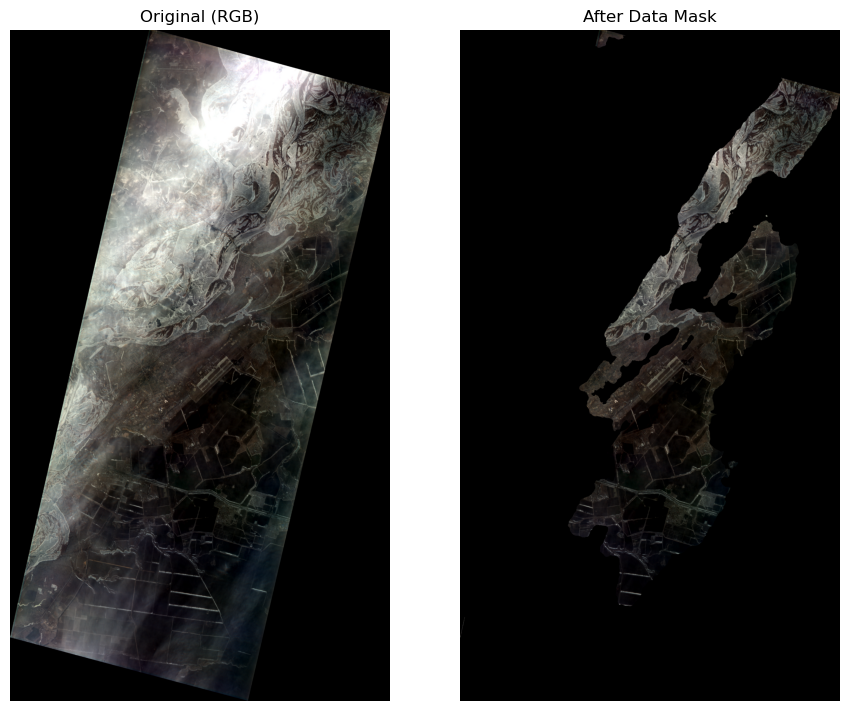

In [12]:
with rasterio.open(q_paths["Cloud optimized GeoTiff"]) as src:
    small_raw = src.read(
        q_bands, out_shape=(len(q_bands), src.height // 4, src.width // 4)
    )

with rasterio.open(q_paths["Data Mask"]) as src:
    small_clear = src.read(1, out_shape=(src.height // 4, src.width // 4)) == 1

small = small_raw.astype(np.float32)
small[small_raw == q_nodata] = np.nan
small *= q_scale
small = np.moveaxis(small, 0, -1)

q_overview = np.nan_to_num(
    np.stack([stretch(small[:, :, i]) for i in range(3)], axis=-1), nan=0
)
q_overview_clear = np.where(small_clear[:, :, None], q_overview, 0)

fig, axes = plt.subplots(1, 2, figsize=(9, 7), layout="constrained")
for ax, image, title in zip(
    axes,
    [q_overview, q_overview_clear],
    ["Original (RGB)", "After Data Mask"],
):
    ax.imshow(image)
    ax.set_title(title)
    ax.axis("off")
plt.show()

Once we apply the mask, not much of the scene is left. Very little of it is cloud, but a large part is flagged as haze, which is why the clear area is much smaller than it was for Ohio. The counts at the end of this section give the exact figures.

700 nm: 9,481 interpolated pixels
1 of 31 bands affected


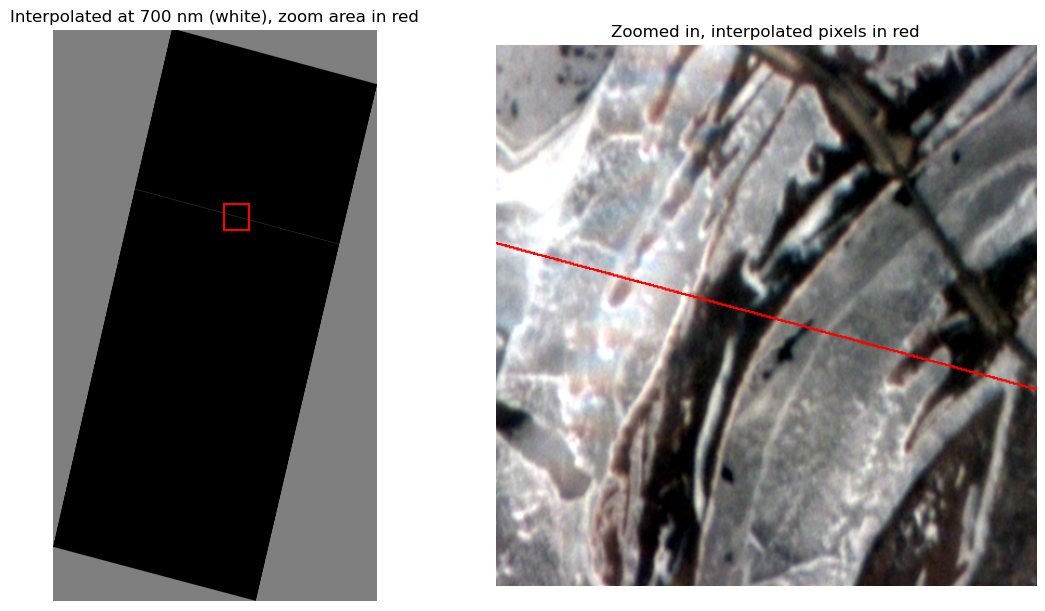

In [13]:
interpolated_counts = []

with rasterio.open(q_paths["Pixel Quality Mask"]) as src:
    q_quality_ok = np.ones(src.shape, dtype=bool)
    for i in src.indexes:
        flags = src.read(i) == 1
        interpolated_counts.append(np.count_nonzero(flags))
        q_quality_ok &= ~flags

affected = [i for i, count in enumerate(interpolated_counts, start=1) if count]
for i in affected:
    print(
        f"{round(q_wavelengths[i - 1])} nm: {interpolated_counts[i - 1]:,} interpolated pixels"
    )
print(f"{len(affected)} of {len(interpolated_counts)} bands affected")

worst_band = int(np.argmax(interpolated_counts)) + 1
worst_nm = round(q_wavelengths[worst_band - 1])
with rasterio.open(q_paths["Pixel Quality Mask"]) as src:
    worst_raw = src.read(worst_band)
worst_flags = worst_raw == 1

# The flagged pixels run most of the way across the scene, so crop a fixed
# window around the middle.
rows, cols = np.nonzero(worst_flags)
half = 250
r, c = int(np.median(rows)), int(np.median(cols))
r0, c0 = max(r - half, 0), max(c - half, 0)
r1, c1 = min(r + half, worst_flags.shape[0]), min(c + half, worst_flags.shape[1])
window = Window(c0, r0, c1 - c0, r1 - r0)

# Read only that window of the imagery instead of full scene.
with rasterio.open(q_paths["Cloud optimized GeoTiff"]) as src:
    q_raw = src.read(q_bands, window=window)

q_reflectance = q_raw.astype(np.float32)
q_reflectance[q_raw == q_nodata] = np.nan
q_reflectance *= q_scale
q_rgb = np.moveaxis(q_reflectance, 0, -1)

crop = np.nan_to_num(
    np.stack([stretch(q_rgb[:, :, i]) for i in range(3)], axis=-1), nan=0
)
crop[worst_flags[r0:r1, c0:c1]] = [1, 0, 0]

fig, axes = plt.subplots(1, 2, figsize=(11, 6), layout="constrained")
axes[0].imshow(
    np.ma.masked_where(worst_raw == 255, worst_flags), cmap=grey, vmin=0, vmax=1
)
axes[0].add_patch(
    plt.Rectangle((c0, r0), c1 - c0, r1 - r0, edgecolor="red", facecolor="none", lw=1.5)
)
axes[0].set_title(f"Interpolated at {worst_nm} nm (white), zoom area in red")
axes[1].imshow(crop)
axes[1].set_title("Zoomed in, interpolated pixels in red")
for ax in axes:
    ax.axis("off")
plt.show()

One band is affected, at 700 nm, and the rest are fine. The left panel looks almost empty because a few thousand pixels out of millions are not visible at full extent. You can see a faint line if you look closely.

The zoomed panel shows a thin line running diagonally across the scene. A streak like this likely comes from the sensor and the values along it were filled in instead of measured. 

As you can see, interpolated pixels occur only rarely in Wyvern images, but it is good to know it can happen.

Your display bands can be clean while the band your analysis depends on is not. 700 nm sits in the red edge, which is where an index like NDCI looks, so you could calculate it on this scene and never see from the RGB that part of it rests on interpolated values.

## Using both masks together

The two masks are independent, so you can apply both. Keep the pixels that the clear band calls clear and that have no quality condition in any band.

Here that is a strict version, since it drops a pixel interpolated in any band at all. For a specific index you would narrow it to the bands that index uses and keep more data.

In [14]:
with rasterio.open(q_paths["Data Mask"]) as src:
    q_clear_band = src.read(1)

q_footprint = q_clear_band != 255
q_clear = q_clear_band == 1
q_n = np.count_nonzero(q_footprint)

print(f"Kept after Data Mask: {100 * np.count_nonzero(q_clear) / q_n:.2f}%")
print(
    f"Kept after both masks: {100 * np.count_nonzero(q_clear & q_quality_ok) / q_n:.2f}%"
)

Kept after Data Mask: 32.08%
Kept after both masks: 32.07%


## What is next
A few ways to take this further:

- Apply the same masks to a different scene from the [Wyvern Open Data Program](https://opendata.wyvern.space) and see how much the cloud, haze, and shadow balance changes
- Use this clear mask as the starting point for [Water Quality Monitoring with Python](https://knowledge.wyvern.space/docs/tutorials/python/water_quality_indices), which combines the clear band with a water polygon
- Try [Index Calculations with Python](https://knowledge.wyvern.space/docs/tutorials/python/index_calculation) and compare an index before and after masking to see how much the clouds were shifting your results

References: [Usable Data Mask](https://guide.wyvern.space/data-product-guide/file-formats/usable-data-mask/) and [Pixel Quality Mask](https://guide.wyvern.space/data-product-guide/file-formats/pixel-quality-mask/).